In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv(r"D:\Ironhack\amz_uk_price_prediction_dataset.csv")

In [2]:
df.columns, df.dtypes

(Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
        'boughtInLastMonth', 'category'],
       dtype='object'),
 uid                    int64
 asin                  object
 title                 object
 stars                float64
 reviews                int64
 price                float64
 isBestSeller            bool
 boughtInLastMonth      int64
 category              object
 dtype: object)

In [3]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
crosstab_prop = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
crosstab_prop

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [5]:
sorted_prop = crosstab_prop.sort_values(by=True, ascending=False)
sorted_prop

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


In [6]:
from scipy.stats import chi2_contingency
p_value = chi2_contingency (crosstab_result)[1]
p_value 

np.float64(0.0)

In [7]:
from scipy.stats.contingency import association
association(crosstab_result,method = "cramer")

0.1222829439760564

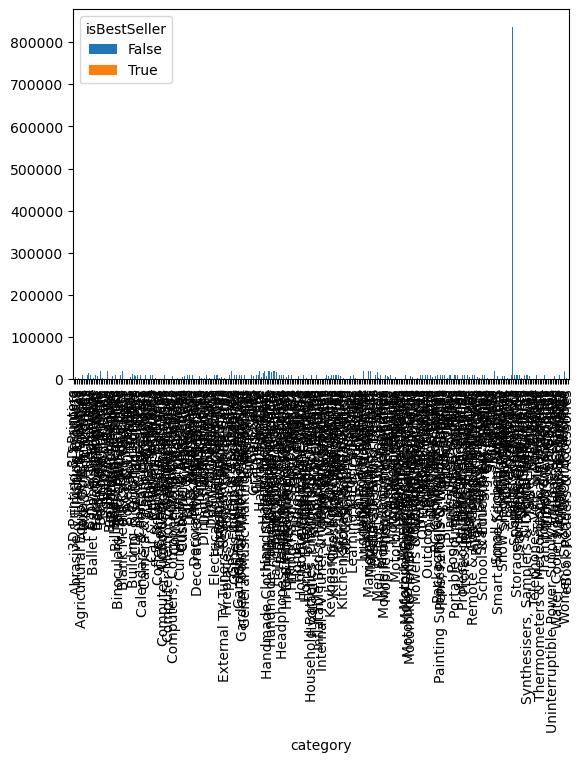

In [8]:
crosstab_result.plot(kind="bar", stacked=True)

plt.show()

In [9]:


def remove_outliers_iqr(df):
    Q1 = df['price'].quantile(0.25)
    Q3 = df['price'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clean = df[
        (df['price'] >= lower_bound) & 
        (df['price'] <= upper_bound)
    ]

    return df_clean

In [10]:
df_no_outliers = remove_outliers_iqr(df)


In [11]:
top20 = df_no_outliers['category'].value_counts().nlargest(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20)]

C:\Users\vgold\AppData\Local\Temp\ipykernel_11664\287721544.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, 'Handmade Home & Kitchen Products'),
  Text(1, 0, 'Sports & Outdoors'),
  Text(2, 0, 'Handmade Gifts'),
  Text(3, 0, 'Fragrances'),
  Text(4, 0, 'Skin Care'),
  Text(5, 0, 'Birthday Gifts'),
  Text(6, 0, 'Handmade Kitchen & Dining'),
  Text(7, 0, 'Bath & Body'),
  Text(8, 0, 'Manicure & Pedicure Products'),
  Text(9, 0, 'Beauty'),
  Text(10, 0, 'Handmade Artwork'),
  Text(11, 0, 'Make-up'),
  Text(12, 0, 'Baby'),
  Text(13, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(14, 0, 'Handmade Home Décor'),
  Text(15, 0, 'Men'),
  Text(16, 0, 'Luggage and travel gear'),
  Text(17, 0, 'Handmade Jewellery'),
  Text(18, 0, 'Women'),
  Text(19, 0, 'Hair Care')])

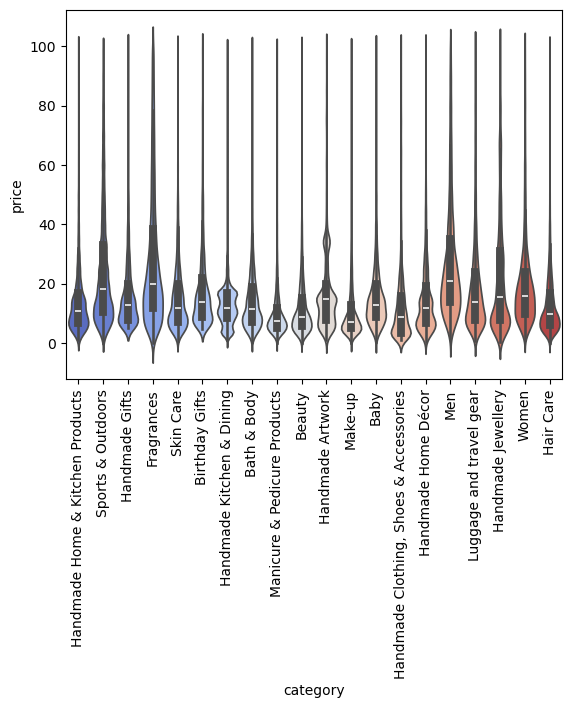

In [12]:

sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm")
plt.xticks(rotation=90)

In [13]:
df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)


category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

In [15]:
top10 = df_no_outliers['category'].value_counts().nlargest(10).index

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top10)]


In [16]:
avg_price = df_top10.groupby('category')['price'].mean().sort_values(ascending = False)

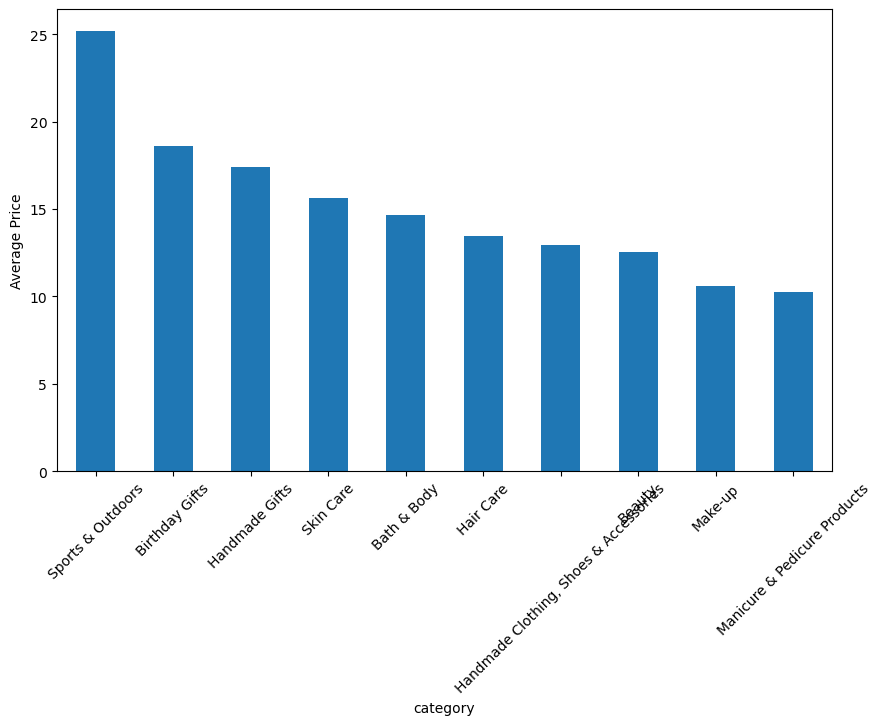

In [17]:
avg_price.plot(kind='bar', figsize=(10,6))
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

In [18]:
df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)


category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

In [19]:
top10 = df['category'].value_counts().nlargest(10).index
df_top10 = df[df['category'].isin(top10)]

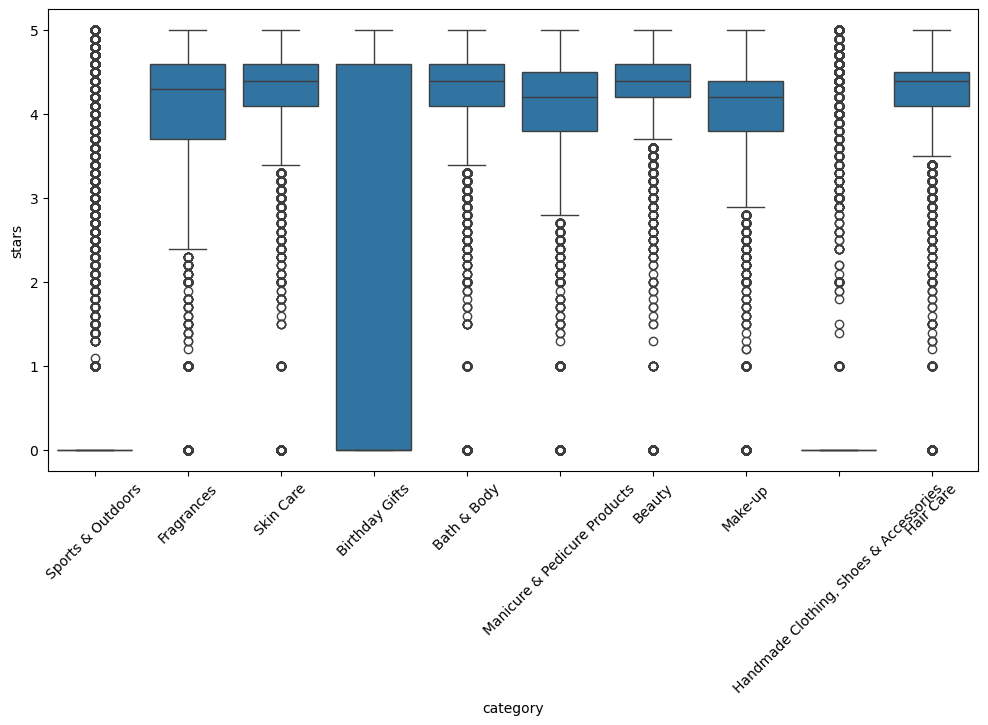

In [20]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_top10, x='category', y='stars')
plt.xticks(rotation=45)
plt.show()

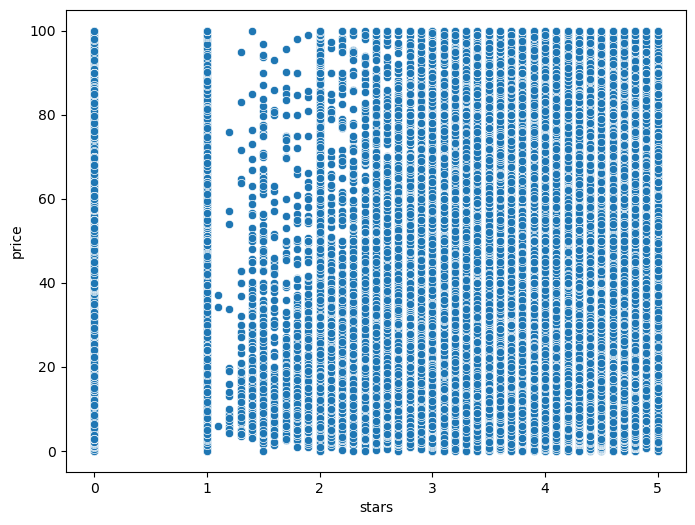

In [21]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_no_outliers, x='stars', y='price')
plt.show()

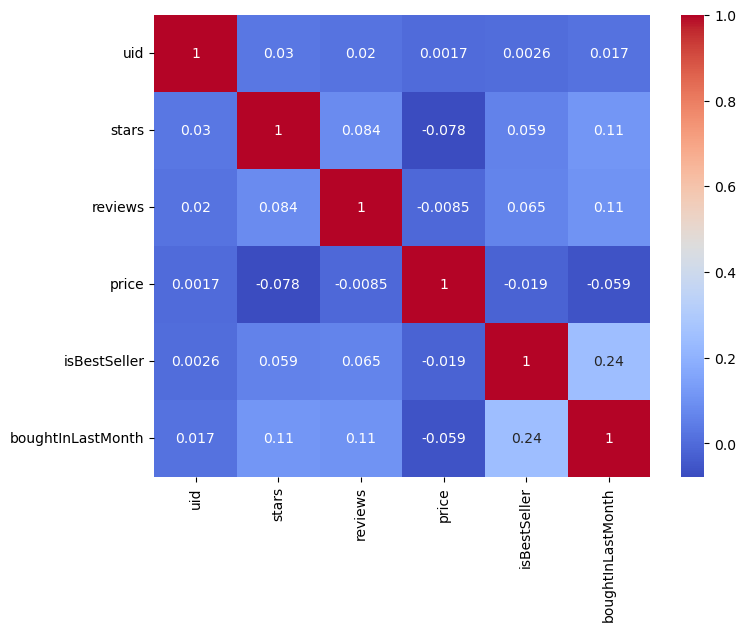

In [22]:
plt.figure(figsize=(8,6))
sns.heatmap(df_no_outliers.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm')
plt.show()